# Phase 1: Feature Extraction & Export
Turn each patient's posts into numbers that describe their language and online behavior, then export the tables for model training (Phase 2).

## Step 1: Load the clean posts
Load the cleaned, anonymized posts from notebook 02.

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "phase1_data" else Path.cwd()
df = pd.read_csv(ROOT / "data" / "interim" / "clean_posts.csv", dtype={"text": str}, encoding="utf-8-sig")
df["date"] = pd.to_datetime(df["date"])

print("Posts:", len(df), "| Own-words posts:", (df["copied"] == 0).sum(), "| Patients:", df["patient"].nunique())
print(df.drop_duplicates("patient")["label"].value_counts())

Posts: 47935 | Own-words posts: 40048 | Patients: 209
label
1    148
0     61
Name: count, dtype: int64


## Step 2: Split patients into train and test
Split patients (not posts) 80% train / 20% test, keeping the same Normal/Impaired ratio in both. No patient appears in both sets, so the test is fair.

In [2]:
from sklearn.model_selection import train_test_split

patients = df.drop_duplicates("patient")[["patient", "label"]]
train_ids, test_ids = train_test_split(
    patients["patient"], test_size=0.2, stratify=patients["label"], random_state=42
)
split = pd.Series("train", index=patients["patient"])
split[test_ids.values] = "test"
df["split"] = df["patient"].map(split)

summary = df.drop_duplicates("patient").groupby(["split", "label"]).size().unstack()
print(summary)
print("Overlap between train and test:", len(set(train_ids) & set(test_ids)))

(ROOT / "data" / "processed").mkdir(parents=True, exist_ok=True)
pd.Series(sorted(test_ids), name="patient").to_csv(ROOT / "data" / "processed" / "test_patients.csv", index=False)

label   0    1
split         
test   12   30
train  49  118
Overlap between train and test: 0


## Step 3: Word lists for Arabic language features
Define the pronouns and vague "filler" words (Egyptian and standard Arabic, normalized), and split each own-words post into words.

In [4]:
TAG_RE  = re.compile(r"\[(EMAIL|PERSON|PHONE|ID|SELF)\]")
WORD_RE = re.compile(r"[\u0600-\u06FFa-z]+")
SENT_RE = re.compile(r"[.!?;,\n]+")

PRONOUNS = {"انا", "انت", "انتي", "هو", "هي", "احنا", "نحن", "انتو", "انتم", "هم", "هما",
            "ده", "دي", "دا", "دول", "هذا", "هذه", "ذلك", "تلك", "اللي", "الي", "i", "you", "he", "she", "it", "we", "they"}
FILLERS  = {"حاجه", "حاجات", "شي", "شيء", "كده", "كدا", "يعني", "بقي", "اهو", "ايه", "مش", "عارف",
            "عارفه", "thing", "stuff"}

df["text"] = df["text"].fillna("").astype(str)

own = df[df["copied"] == 0].copy()
own["tokens"] = [WORD_RE.findall(TAG_RE.sub(" ", t)) for t in own["text"]]
own["n_tok"] = own["tokens"].str.len()
own = own[own["n_tok"] > 0]

print("Own-words posts with words:", len(own), "| total words:", own["n_tok"].sum())
print("Average words per post:", round(own["n_tok"].mean(), 1))

Own-words posts with words: 40020 | total words: 963720
Average words per post: 24.1


## Step 4: Per-post language measurements
For each own-words post, measure word length, sentence length, pronoun use, vague-word use and repeated phrases.

In [5]:
def repeated_bigrams(tokens):
    bigrams = list(zip(tokens, tokens[1:]))
    return len(bigrams) - len(set(bigrams)) if bigrams else 0

own["avg_word_len"]  = [np.mean([len(w) for w in t]) for t in own["tokens"]]
own["n_sent"]        = [max(1, len([s for s in SENT_RE.split(x) if s.strip()])) for x in own["text"]]
own["words_per_sent"] = own["n_tok"] / own["n_sent"]
own["n_pron"]        = [sum(w in PRONOUNS for w in t) for t in own["tokens"]]
own["n_fill"]        = [sum(w in FILLERS for w in t) for t in own["tokens"]]
own["n_rep_bigrams"] = [repeated_bigrams(t) for t in own["tokens"]]
own["n_bigrams"]     = (own["n_tok"] - 1).clip(lower=0)

print(own[["n_tok", "avg_word_len", "words_per_sent", "n_pron", "n_fill", "n_rep_bigrams"]].describe().round(2))

          n_tok  avg_word_len  words_per_sent    n_pron    n_fill  \
count  40020.00      40020.00        40020.00  40020.00  40020.00   
mean      24.08          4.53           14.05      0.65      0.15   
std       24.70          0.72           15.67      1.27      0.60   
min        1.00          1.00            0.07      0.00      0.00   
25%        7.00          4.06            5.00      0.00      0.00   
50%       16.00          4.47            9.00      0.00      0.00   
75%       32.00          4.93           17.00      1.00      0.00   
max      144.00         19.00          138.00     21.00     18.00   

       n_rep_bigrams  
count       40020.00  
mean            1.11  
std             3.77  
min             0.00  
25%             0.00  
50%             0.00  
75%             0.00  
max            79.00  


## Step 5: Per-patient features
Combine each patient's posts into one row of features: writing features from their own words (vocabulary richness, sentence length, pronouns, vague words, repetition) and behavior features from all posts (activity, night posting, emojis, copying).

In [6]:
from collections import Counter

def mattr(tokens, w=50):
    if len(tokens) < w:
        return len(set(tokens)) / max(len(tokens), 1)
    c = Counter(tokens[:w]); vals = [len(c) / w]
    for i in range(w, len(tokens)):
        out_t = tokens[i - w]; c[out_t] -= 1
        if c[out_t] == 0: del c[out_t]
        c[tokens[i]] += 1; vals.append(len(c) / w)
    return float(np.mean(vals))

def hapax_ratio(tokens, w=100):
    chunks = [tokens[i:i + w] for i in range(0, len(tokens) - w + 1, w)] or [tokens]
    return float(np.mean([sum(v == 1 for v in Counter(ch).values()) / len(ch) for ch in chunks]))

own = own.sort_values(["patient", "date"])
rows = []
for pid, g in own.groupby("patient"):
    toks = [w for t in g["tokens"] for w in t]
    rows.append({
        "patient": pid,
        "own_posts": len(g),
        "avg_words_per_post": g["n_tok"].mean(),
        "avg_word_length": g["avg_word_len"].mean(),
        "avg_sentence_length": g["n_tok"].sum() / g["n_sent"].sum(),
        "mattr": mattr(toks),
        "hapax_ratio": hapax_ratio(toks),
        "pronoun_ratio": g["n_pron"].sum() / g["n_tok"].sum(),
        "filler_ratio": g["n_fill"].sum() / g["n_tok"].sum(),
        "repetition_rate": g["n_rep_bigrams"].sum() / max(g["n_bigrams"].sum(), 1),
    })
writing = pd.DataFrame(rows)

beh = df.groupby("patient").agg(
    n_posts=("text", "size"),
    first_date=("date", "min"),
    last_date=("date", "max"),
    night_post_ratio=("date", lambda d: d.dt.hour.between(0, 4).mean()),
    emoji_per_post=("emoji_count", "mean"),
    elongation_per_post=("elongation_count", "mean"),
    english_share=("mostly_english", "mean"),
    copied_share=("copied", "mean"),
    label=("label", "first"), group=("group", "first"), moca=("moca", "first"), split=("split", "first"),
).reset_index()
beh["active_months"] = ((beh["last_date"] - beh["first_date"]).dt.days / 30.44).clip(lower=1)
beh["posts_per_month"] = beh["n_posts"] / beh["active_months"]

features = writing.merge(beh.drop(columns=["first_date", "last_date"]), on="patient")
print("Patients:", len(features), "| Features:", features.shape[1])
features.drop(columns=["patient", "group", "split"]).describe().round(3).T

Patients: 209 | Features: 22


,count,mean,std,min,25%,50%,75%,max
own_posts,209.0,191.483,155.440,5.000,53.000,179.000,289.000,840.000
avg_words_per_post,209.0,23.970,10.833,3.668,16.624,22.448,28.961,81.312
avg_word_length,209.0,4.511,0.230,3.894,4.394,4.489,4.609,5.705
avg_sentence_length,209.0,11.621,5.865,1.646,8.643,10.425,12.553,51.953
mattr,209.0,0.869,0.044,0.666,0.853,0.878,0.895,0.948
hapax_ratio,209.0,0.698,0.084,0.343,0.660,0.714,0.756,0.875
pronoun_ratio,209.0,0.028,0.012,0.000,0.021,0.026,0.032,0.087
filler_ratio,209.0,0.006,0.005,0.000,0.002,0.005,0.009,0.032
repetition_rate,209.0,0.044,0.041,0.000,0.020,0.032,0.053,0.270
n_posts,209.0,229.354,179.538,6.000,63.000,206.000,349.000,844.000


## Step 6: Change over time (compared to their own past)
For each patient, compare their earlier posts with their later posts. A drop in vocabulary or sentence length, or a rise in repetition and vague words, may signal cognitive decline. This is Neorora's core idea: each person is compared to themselves.

In [7]:
def part_stats(g):
    toks = [w for t in g["tokens"] for w in t]
    return {
        "mattr": mattr(toks),
        "avg_words_per_post": g["n_tok"].mean(),
        "avg_sentence_length": g["n_tok"].sum() / g["n_sent"].sum(),
        "pronoun_ratio": g["n_pron"].sum() / g["n_tok"].sum(),
        "filler_ratio": g["n_fill"].sum() / g["n_tok"].sum(),
        "repetition_rate": g["n_rep_bigrams"].sum() / max(g["n_bigrams"].sum(), 1),
    }

MIN_PER_HALF = 5
change_rows = []
for pid, g in own.groupby("patient"):
    g = g.sort_values("date")
    half = len(g) // 2
    row = {"patient": pid}
    if half >= MIN_PER_HALF:
        early, late = part_stats(g.iloc[:half]), part_stats(g.iloc[half:])
        for k in early:
            row[f"{k}_change"] = late[k] - early[k]
    change_rows.append(row)

change = pd.DataFrame(change_rows)
print("Patients with enough posts for change features:", change.drop(columns="patient").notna().all(axis=1).sum(), "of", len(change))

features = features.merge(change, on="patient", how="left")
change_cols = [c for c in features.columns if c.endswith("_change")]
features[change_cols] = features[change_cols].fillna(0)      # too few posts → treat as "no change"

print(features.groupby("group")[change_cols].mean().round(4).T)

Patients with enough posts for change features: 199 of 209
group                       Dementia     MCI  Normal
mattr_change                 -0.0049  0.0109  0.0042
avg_words_per_post_change     0.8403  0.7321  1.4715
avg_sentence_length_change    0.0646  0.8074  0.4532
pronoun_ratio_change         -0.0002  0.0001 -0.0027
filler_ratio_change           0.0009  0.0006  0.0008
repetition_rate_change        0.0070  0.0010 -0.0007


**Result:** Change features computed for 199 of 209 patients. The dementia group shows a drop in vocabulary richness and the largest rise in repetition over time, while the Normal group's posts grow longer, consistent with expected signs of decline (small trends, to be tested by the model).

## Step 7: Charts for the slides
Visualize the data and the main features by group, using training patients only, so the test patients stay unseen.

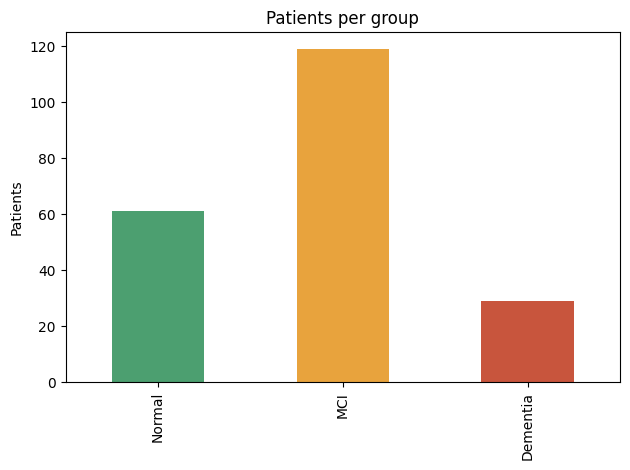

C:\Users\talah\AppData\Local\Temp\ipykernel_26040\1218500350.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_f, x="group", y=col, order=order, palette=palette, ax=ax)
C:\Users\talah\AppData\Local\Temp\ipykernel_26040\1218500350.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_f, x="group", y=col, order=order, palette=palette, ax=ax)
C:\Users\talah\AppData\Local\Temp\ipykernel_26040\1218500350.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_f, x="group", y=col, order=order, palette=palette, ax=ax

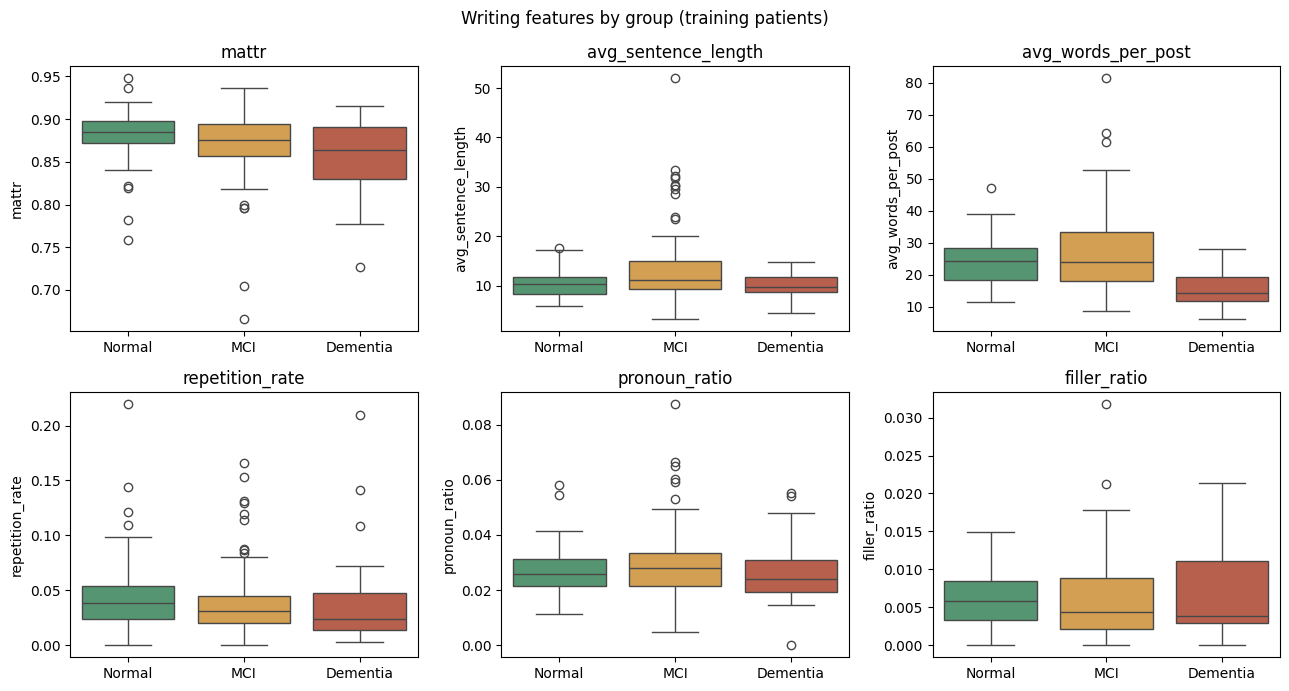

C:\Users\talah\AppData\Local\Temp\ipykernel_26040\1218500350.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train_f, x="group", y=col, order=order, palette=palette, ax=ax, errorbar=None)
C:\Users\talah\AppData\Local\Temp\ipykernel_26040\1218500350.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train_f, x="group", y=col, order=order, palette=palette, ax=ax, errorbar=None)
C:\Users\talah\AppData\Local\Temp\ipykernel_26040\1218500350.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train_f, x="group", y=col, order

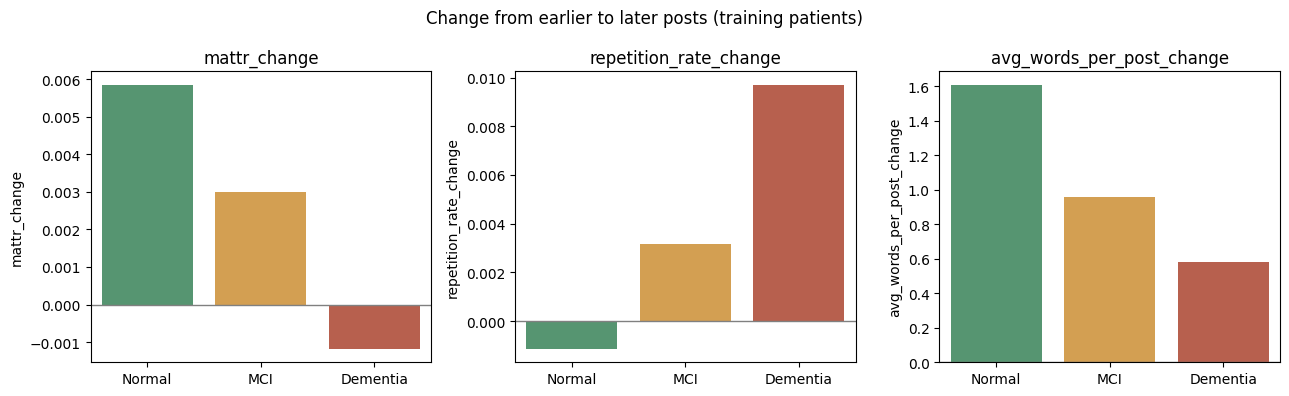

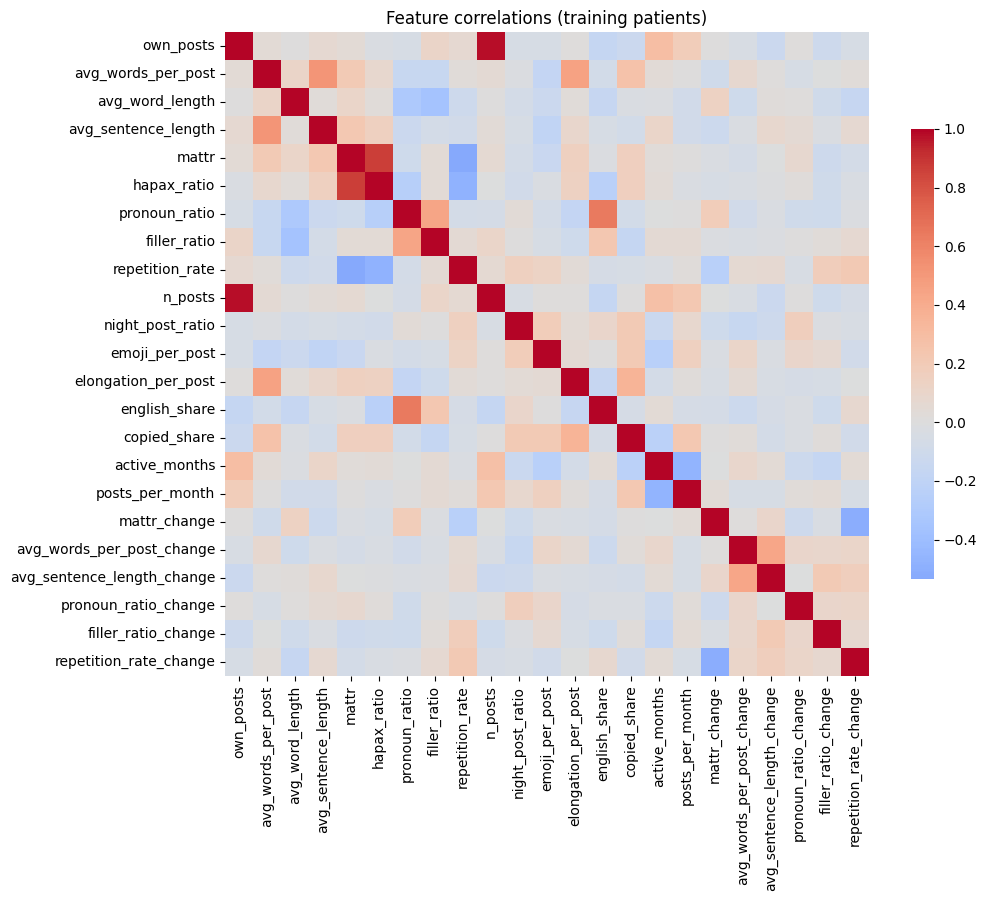

Charts saved in phase1_data/figures


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

FIG = ROOT / "phase1_data" / "figures"
FIG.mkdir(exist_ok=True)
train_f = features[features["split"] == "train"]
order = ["Normal", "MCI", "Dementia"]
palette = {"Normal": "#4C9F70", "MCI": "#E8A33D", "Dementia": "#C8553D"}

# 1. Patients per group
ax = features["group"].value_counts().reindex(order).plot(kind="bar", color=[palette[g] for g in order])
ax.set_title("Patients per group"); ax.set_ylabel("Patients"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "01_patients_per_group.png", dpi=150); plt.show()

# 2. Main writing features by group
main = ["mattr", "avg_sentence_length", "avg_words_per_post", "repetition_rate", "pronoun_ratio", "filler_ratio"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, main):
    sns.boxplot(data=train_f, x="group", y=col, order=order, palette=palette, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Writing features by group (training patients)")
plt.tight_layout(); plt.savefig(FIG / "02_features_by_group.png", dpi=150); plt.show()

# 3. Change over time by group
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["mattr_change", "repetition_rate_change", "avg_words_per_post_change"]):
    sns.barplot(data=train_f, x="group", y=col, order=order, palette=palette, ax=ax, errorbar=None)
    ax.axhline(0, color="gray", lw=1); ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Change from earlier to later posts (training patients)")
plt.tight_layout(); plt.savefig(FIG / "03_change_by_group.png", dpi=150); plt.show()

# 4. Feature correlations
num = train_f.drop(columns=["patient", "group", "split", "label", "moca"]).select_dtypes("number")
plt.figure(figsize=(11, 9))
sns.heatmap(num.corr(), cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.title("Feature correlations (training patients)")
plt.tight_layout(); plt.savefig(FIG / "04_correlations.png", dpi=150); plt.show()

print("Charts saved in phase1_data/figures")

Chart 2 (writing features by group):

Words per post: the Dementia group writes much shorter posts. That’s the clearest difference
Vocabulary richness (mattr): Dementia is lower and more spread out

Chart 3 (change over time): your strongest slide 🔥
A clean Normal → MCI → Dementia pattern on all three:

Vocabulary richness rises for Normal, falls for Dementia
Repetition falls for Normal, rises most for Dementia
Post length grows most for Normal, least for Dementia

Chart 4 (correlations), notes for Amal & Juman:

own_posts ≈ n_posts, and mattr ≈ hapax_ratio (nearly identical), so they should keep one of each pair for logistic regression / SVM
pronoun_ratio is linked to english_share (English pronouns count too)

## Step 8: Export the features for Phase 2
Save the train and test feature tables (numbers only, no text). The test patients are kept separate for the final, one-time evaluation. MoCA scores and group names are saved separately, since they are not model inputs.

In [9]:
PROC = ROOT / "data" / "processed"
info_cols = ["patient", "group", "moca", "split"]
feature_cols = [c for c in features.columns if c not in info_cols + ["label"]]

for name in ["train", "test"]:
    part = features[features["split"] == name]
    part[["patient"] + feature_cols + ["label"]].to_csv(PROC / f"features_{name}.csv", index=False)
features[info_cols + ["label"]].to_csv(PROC / "patient_info.csv", index=False)

print("Features:", len(feature_cols))
print("Train:", (features["split"] == "train").sum(), "patients | Test:", (features["split"] == "test").sum(), "patients")
print("Feature columns:", feature_cols)

Features: 23
Train: 167 patients | Test: 42 patients
Feature columns: ['own_posts', 'avg_words_per_post', 'avg_word_length', 'avg_sentence_length', 'mattr', 'hapax_ratio', 'pronoun_ratio', 'filler_ratio', 'repetition_rate', 'n_posts', 'night_post_ratio', 'emoji_per_post', 'elongation_per_post', 'english_share', 'copied_share', 'active_months', 'posts_per_month', 'mattr_change', 'avg_words_per_post_change', 'avg_sentence_length_change', 'pronoun_ratio_change', 'filler_ratio_change', 'repetition_rate_change']
